<a href="https://colab.research.google.com/github/ibader85/PredictiveAnalytics/blob/main/27_Association_Rules_Using_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

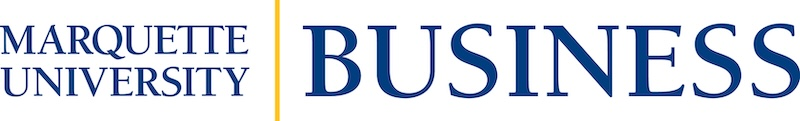

# BUAN 3065: Unlocking Business Insights with Predictive Analytics
# Association Rules Using R

Instructor: Dr. Badar Al Lawati

**Disclaimer:** the content in this notebook is based on the content in Chapter 14 of Business Analytics by Sanjiv Jaggia, Alison Kelly, Kevin Lertwachara and Leida Chen. ISBN10: 126692602X | ISBN13: 9781266926020

**Problem:** The store manager at an electronics store collects data on the last 100
transactions.

Five possible products were purchased: a keyboard, an SD
card, a mouse, a USB drive, and/or a headphone

In [2]:
install.packages('arules')
install.packages('arulesViz')

library(arules)
library(arulesViz)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘gridExtra’, ‘RcppArmadillo’, ‘iterators’, ‘zoo’, ‘crosstalk’, ‘ggforce’, ‘ggrepel’, ‘viridis’, ‘tidygraph’, ‘graphlayouts’, ‘ca’, ‘colorspace’, ‘foreach’, ‘gclus’, ‘qap’, ‘registry’, ‘TSP’, ‘lmtest’, ‘DT’, ‘ggraph’, ‘igraph’, ‘plotly’, ‘scatterplot3d’, ‘seriation’, ‘vcd’, ‘visNetwork’


Loading required package: Matrix


Attaching package: ‘arules’


The following objects are masked from ‘package:base’:

    abbreviate, write




In [5]:
# We use the read.transactions function to read the data and store
# the data in a new transaction object called myData

myData <- read.transactions('/content/Transaction.csv', format = 'basket', sep = ',')
inspect(myData[1:5])

Warning message in readLines(file, encoding = encoding):
“incomplete final line found on '/content/Transaction.csv'”


    items                              
[1] {headphone, keyboard, mouse}       
[2] {keyboard, mouse, SDcard}          
[3] {headphone}                        
[4] {keyboard}                         
[5] {keyboard, mouse, SDcard, USBdrive}


We use the itemFrequency and the itemFrequencyPlot functions to
check the frequency of the items

headphone  keyboard     mouse    SDcard  USBdrive 
     0.32      0.67      0.49      0.62      0.19

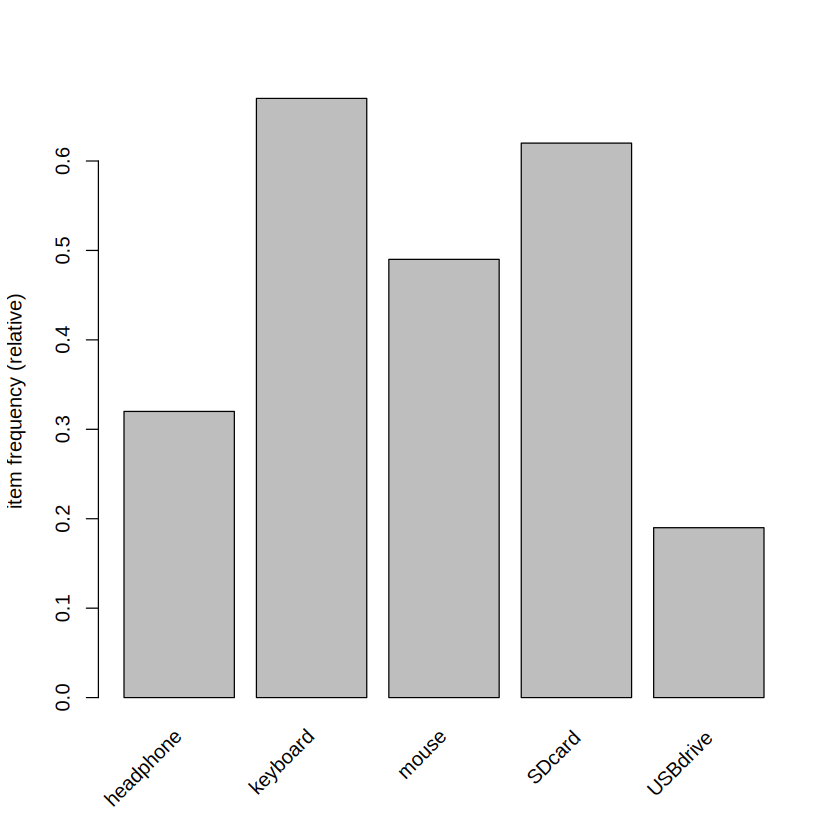

In [6]:
itemFrequency(myData)
itemFrequencyPlot(myData)

We use the Apriori function to conduct association rule analysis


We set minimum values of supp (support) and conf (confidence)
at 0.1 and 0.5, respectively

Practitioners usually experiment with
different support and confidence thresholds to see whether or not
interesting results might emerge

Inspecting the lift ratios can also help determine these thresholds. (If you do
not specify any parameter values, the default minimum support
and confidence values will be set at 0.1 and 0.8, respectively.)

We
also set the *minlen* option to 2 to prevent R from displaying
association rules without an antecedent

In [7]:
rules <- apriori(myData, parameter = list(minlen = 2, supp=0.1, conf=0.5))

Apriori

Parameter specification:
 confidence minval smax arem  aval originalSupport maxtime support minlen
        0.5    0.1    1 none FALSE            TRUE       5     0.1      2
 maxlen target  ext
     10  rules TRUE

Algorithmic control:
 filter tree heap memopt load sort verbose
    0.1 TRUE TRUE  FALSE TRUE    2    TRUE

Absolute minimum support count: 10 

set item appearances ...[0 item(s)] done [0.00s].
set transactions ...[5 item(s), 100 transaction(s)] done [0.00s].
sorting and recoding items ... [5 item(s)] done [0.00s].
creating transaction tree ... done [0.00s].
checking subsets of size 1 2 3 done [0.00s].
writing ... [9 rule(s)] done [0.00s].
creating S4 object  ... done [0.00s].


In [10]:
# To view the rules sorted by their lift ratios, we use the sort
# function to sort the rules. We use the by and decreasing options to
# sort by the lift ratio in descending order

srules <- sort(rules, by = 'lift', decreasing = TRUE)

In [11]:
inspect(srules)

    lhs                      rhs        support confidence coverage lift     
[1] {keyboard}            => {SDcard}   0.55    0.8208955  0.67     1.3240250
[2] {SDcard}              => {keyboard} 0.55    0.8870968  0.62     1.3240250
[3] {mouse, SDcard}       => {keyboard} 0.23    0.8846154  0.26     1.3203215
[4] {keyboard, mouse}     => {SDcard}   0.23    0.7931034  0.29     1.2791991
[5] {headphone, keyboard} => {SDcard}   0.11    0.7857143  0.14     1.2672811
[6] {headphone, SDcard}   => {keyboard} 0.11    0.7857143  0.14     1.1727079
[7] {mouse}               => {keyboard} 0.29    0.5918367  0.49     0.8833384
[8] {USBdrive}            => {keyboard} 0.11    0.5789474  0.19     0.8641005
[9] {mouse}               => {SDcard}   0.26    0.5306122  0.49     0.8558262
    count
[1] 55   
[2] 55   
[3] 23   
[4] 23   
[5] 11   
[6] 11   
[7] 29   
[8] 11   
[9] 26   


To reduce overplotting, jitter is added! Use jitter = 0 to prevent jitter.



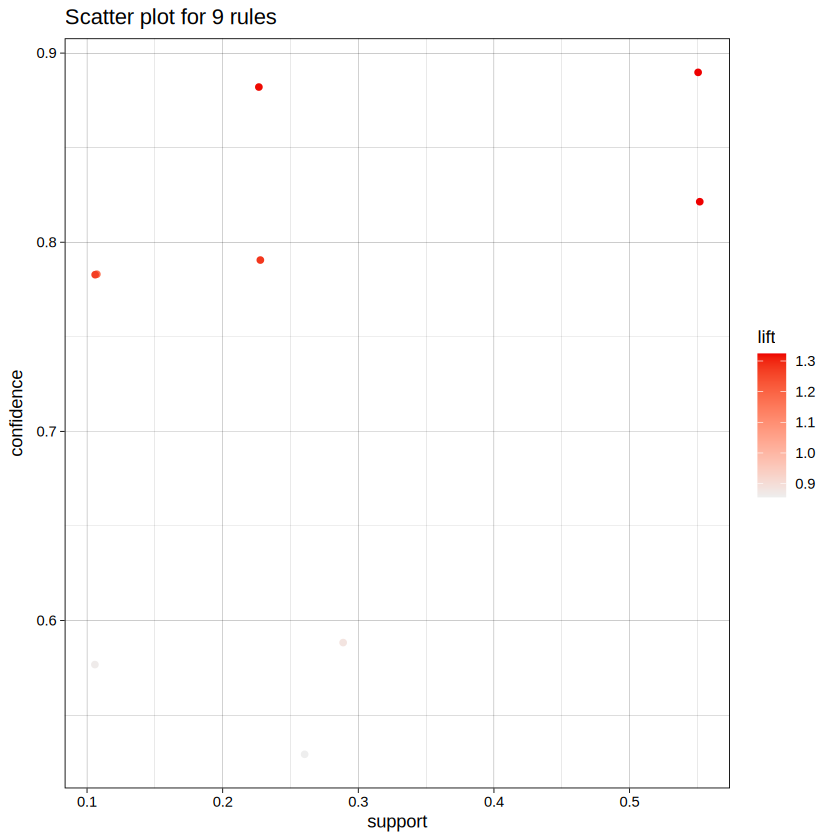

In [12]:
plot(rules)

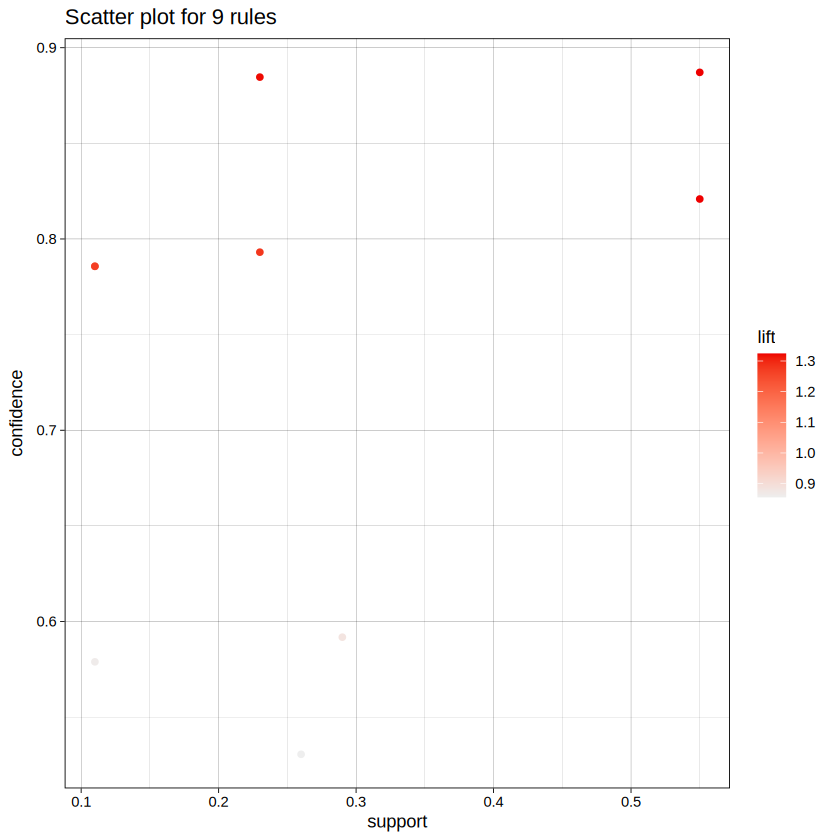

In [15]:
plot(rules, control = list(jitter = 0))